In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
import matplotlib.pyplot as plt

In [3]:
path = r"C:\Users\ritik\Desktop\plant disese\PlantVillage"

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    path,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    path,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.


In [4]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128,128,3)
)

# freeze base model
base_model.trainable = False

9406464/9406464 [==============================] - 1s 0us/step


In [5]:
x = base_model.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)

output = layers.Dense(train_data.num_classes, activation='softmax')(x)

model = models.Model(inputs=base_model.input, outputs=output)

In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [7]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
517/517 [==============================] - 79s 149ms/step - loss: 0.6060 - accuracy: 0.8020 - val_loss: 0.3796 - val_accuracy: 0.8765
Epoch 2/10
517/517 [==============================] - 77s 149ms/step - loss: 0.2949 - accuracy: 0.9023 - val_loss: 0.3566 - val_accuracy: 0.8787
Epoch 3/10
517/517 [==============================] - 76s 148ms/step - loss: 0.2109 - accuracy: 0.9290 - val_loss: 0.3062 - val_accuracy: 0.8986
Epoch 4/10
517/517 [==============================] - 77s 149ms/step - loss: 0.1632 - accuracy: 0.9453 - val_loss: 0.3204 - val_accuracy: 0.8974
Epoch 5/10
517/517 [==============================] - 77s 149ms/step - loss: 0.1274 - accuracy: 0.9565 - val_loss: 0.3000 - val_accuracy: 0.9005
Epoch 6/10
517/517 [==============================] - 111s 216ms/step - loss: 0.0985 - accuracy: 0.9677 - val_loss: 0.2711 - val_accuracy: 0.9168
Epoch 7/10
517/517 [==============================] - 127s 245ms/step - loss: 0.0717 - accuracy: 0.9774 - val_loss: 0.2889 - val_

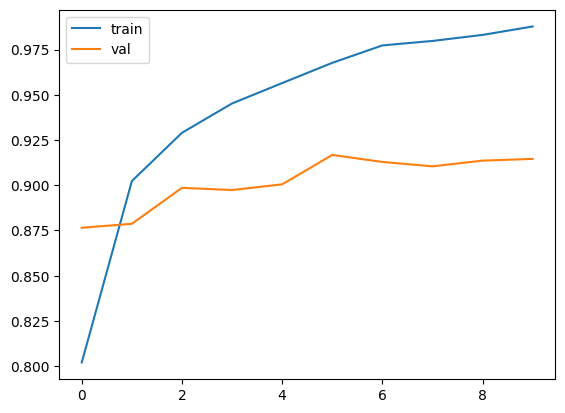

In [8]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.show()

In [9]:
model.save("mobilenet_model.h5")

1/1 [==============================] - 1s 666ms/step


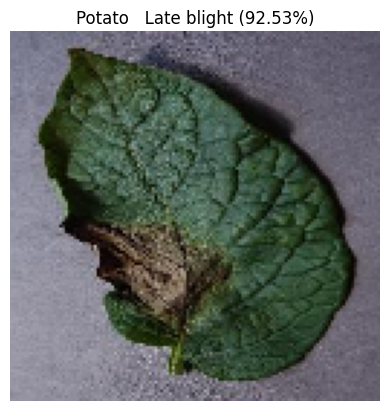

In [10]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

img_path = r"C:\Users\ritik\Downloads\archive (1)\PlantVillage\Potato___Late_blight\fc9b06c8-7c63-445d-9858-a5a0c7be719b___RS_LB 3273.JPG"

img = image.load_img(img_path, target_size=(128,128))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)
pred_index = np.argmax(prediction)

class_names = list(train_data.class_indices.keys())

predicted_class = class_names[pred_index]
confidence = prediction[0][pred_index] * 100

plt.imshow(img)
plt.axis('off')
plt.title(f"{predicted_class.replace('_',' ')} ({confidence:.2f}%)")
plt.show()